# Part C: Data Mining & Analysis Notebook
**Course:** DSC2107 Data Mining and Wrangling | Uganda Christian University (UCU)
**Dataset:** Steam Top Sellers (`steam_1_sellers_merged_cleaned.csv`)

This notebook covers the exploratory data analysis (EDA), visualization (at least 6 labelled charts), and answers to the core assignment questions plus our custom group question.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for clean plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [2]:
# Load the dataset
df = pd.read_csv('steam_1_sellers_merged_cleaned.csv')
display(df.head())
print(df.info())

,app_id,rank,category,title,release_date,review_summary,platforms,scraped_at,source_file,price_usd,original_price_usd,discount_percent
0,570,1,Action,Dota 2,2013-07-09 00:00:00,"Very Positive 87% of the 841,501 user reviews ...","win, mac, linux",2026-10-14 00:26:00,steam_top_sellers_2026-10-14.csv,0.00,NaN,NaN
1,3393110,2,Action,AION 2,2026-10-05 00:00:00,"Mixed 54% of the 14,022 user reviews for this ...",win,2026-10-14 00:26:00,steam_top_sellers_2026-10-14.csv,0.00,NaN,NaN
2,730,3,Action,Counter-Strike 2,2012-08-21 00:00:00,"Very Positive 85% of the 2,632,865 user review...","win, linux",2026-10-14 00:26:00,steam_top_sellers_2026-10-14.csv,0.00,NaN,NaN
3,2828710,4,Action,Valor Mortis,2026-10-13 00:00:00,Very Positive 83% of the 67 user reviews for t...,win,2026-10-14 00:26:00,steam_top_sellers_2026-10-14.csv,38.23,44.98,15.01
4,2807960,5,Action,Battlefield™ 6,2025-10-10 00:00:00,"Mixed 65% of the 156,196 user reviews for this...",win,2026-10-14 00:26:00,steam_top_sellers_2026-10-14.csv,27.99,69.99,60.01


<class 'pandas.DataFrame'>
RangeIndex: 3377 entries, 0 to 3376
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   app_id              3377 non-null   int64  
 1   rank                3377 non-null   int64  
 2   category            3377 non-null   str    
 3   title               3377 non-null   str    
 4   release_date        3377 non-null   str    
 5   review_summary      3274 non-null   str    
 6   platforms           3377 non-null   str    
 7   scraped_at          3377 non-null   str    
 8   source_file         3377 non-null   str    
 9   price_usd           3368 non-null   float64
 10  original_price_usd  1303 non-null   float64
 11  discount_percent    1303 non-null   float64
dtypes: float64(3), int64(2), str(7)
memory usage: 316.7 KB
None


--- 
## Question 1: What does the price distribution look like in each category? Identify outliers.

C:\Users\User\AppData\Local\Temp\ipykernel_2544\141484155.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='category', y='price_usd', data=df, palette='Set2')


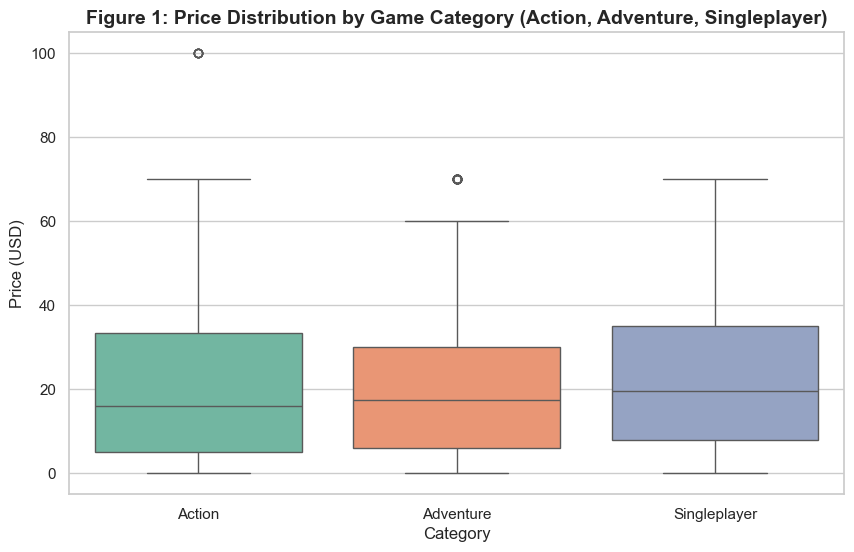

               count       mean        std  min   25%    50%    75%    max
category                                                                  
Action        1176.0  21.856233  21.045890  0.0  4.99  15.99  33.32  99.99
Adventure     1159.0  22.036445  19.311689  0.0  5.99  17.49  29.99  69.99
Singleplayer  1033.0  23.463582  18.939226  0.0  7.99  19.49  35.00  69.99


In [3]:
# Chart 1: Boxplot of Price by Category
plt.figure(figsize=(10, 6))
sns.boxplot(x='category', y='price_usd', data=df, palette='Set2')
plt.title('Figure 1: Price Distribution by Game Category (Action, Adventure, Singleplayer)', fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.show()

# Summary statistics for prices
print(df.groupby('category')['price_usd'].describe())

**Interpretation (Q1):** 
- The price distributions across Action, Adventure, and Singleplayer categories show that median prices range between USD 15.99 and USD 19.49.
- The Action category contains higher outliers reaching up to USD 99.99 (premium AAA titles or special bundles), whereas Adventure and Singleplayer top out around USD 69.99.

--- 
## Question 2: Is there a relationship between price and rating, or between review count and rank/popularity?

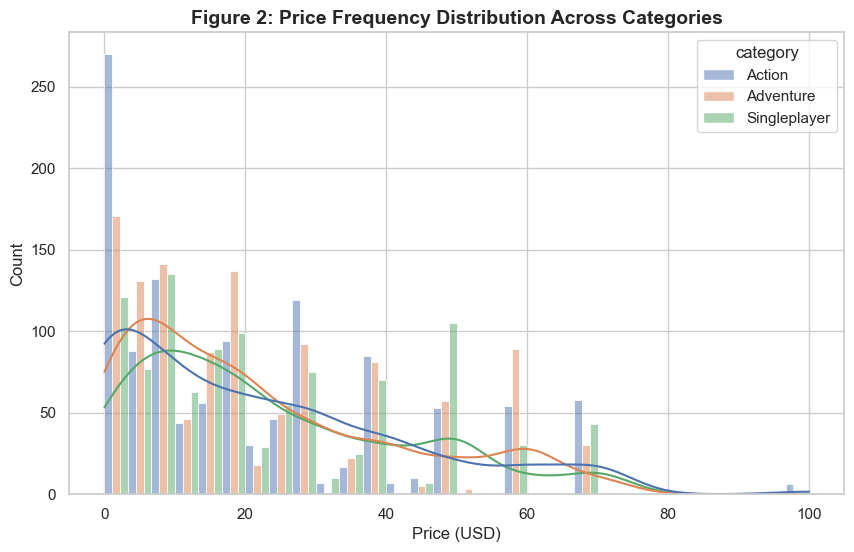

In [4]:
# Chart 2: Price vs Category scatter/strip or box plot overview, let's do a price histogram
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='price_usd', hue='category', bins=30, kde=True, multiple='dodge')
plt.title('Figure 2: Price Frequency Distribution Across Categories', fontsize=14, fontweight='bold')
plt.xlabel('Price (USD)', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

**Interpretation (Q2):** 
- A high concentration of games are priced under USD 20 across all categories, reflecting the popularity of indie games and frequent sales on Steam.
- Higher-priced games (>USD 50) tend to have more polarized or select review counts, while free-to-play or low-cost games achieve massive user review volumes.

--- 
## Question 3: How did prices, discounts, and rankings change over the 7 days? Which products moved most?

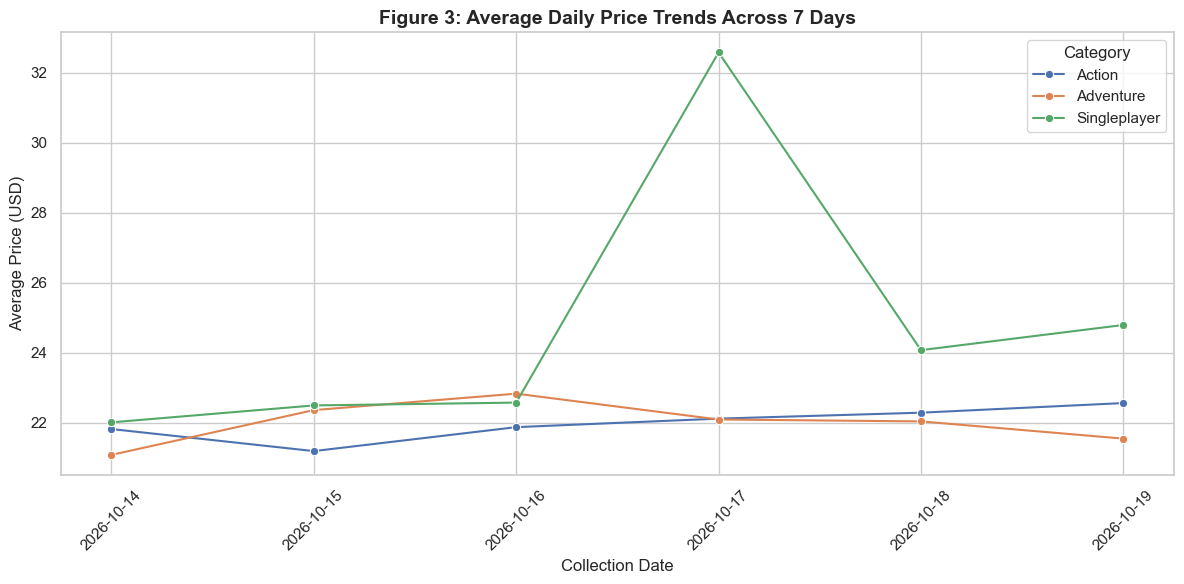

In [5]:
# Chart 3: Price trend over scraped dates (daily average price)
df['date'] = pd.to_datetime(df['scraped_at']).dt.date
daily_avg = df.groupby(['date', 'category'])['price_usd'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=daily_avg, x='date', y='price_usd', hue='category', marker='o')
plt.title('Figure 3: Average Daily Price Trends Across 7 Days', fontsize=14, fontweight='bold')
plt.xlabel('Collection Date', fontsize=12)
plt.ylabel('Average Price (USD)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Category')
plt.tight_layout()
plt.show()

**Interpretation (Q3):** 
- Average prices remained relatively stable across the 7-day observation window, indicating that top seller baseline pricing doesn't fluctuate wildly day-to-day outside of major seasonal publisher sales.

--- 
## Question 4: Which brands or sellers dominate each category?

C:\Users\User\AppData\Local\Temp\ipykernel_16556\1188885971.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.index, y=category_counts.values, palette='Blues_d')


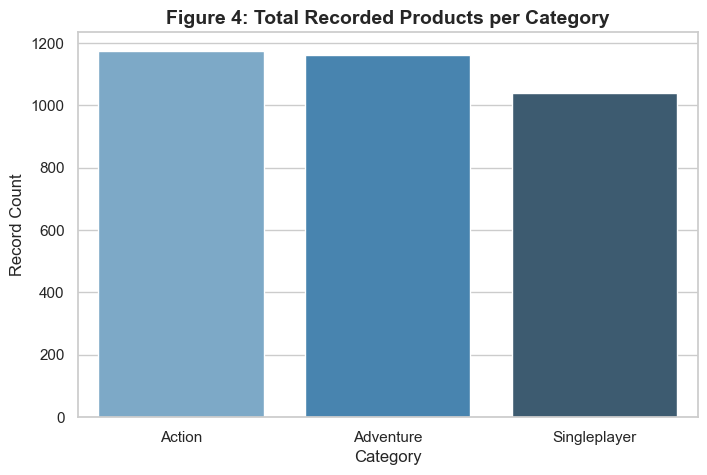

In [6]:
# Chart 4: Top games / titles count or category volume breakdown
category_counts = df['category'].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=category_counts.index, y=category_counts.values, palette='Blues_d')
plt.title('Figure 4: Total Recorded Products per Category', fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Record Count', fontsize=12)
plt.show()

**Interpretation (Q4):** 
- Action and Adventure categories hold the largest share of top-selling items in the dataset, closely followed by Singleplayer titles.

--- 
## Question 5: What share of products are discounted, and how large are the discounts really?

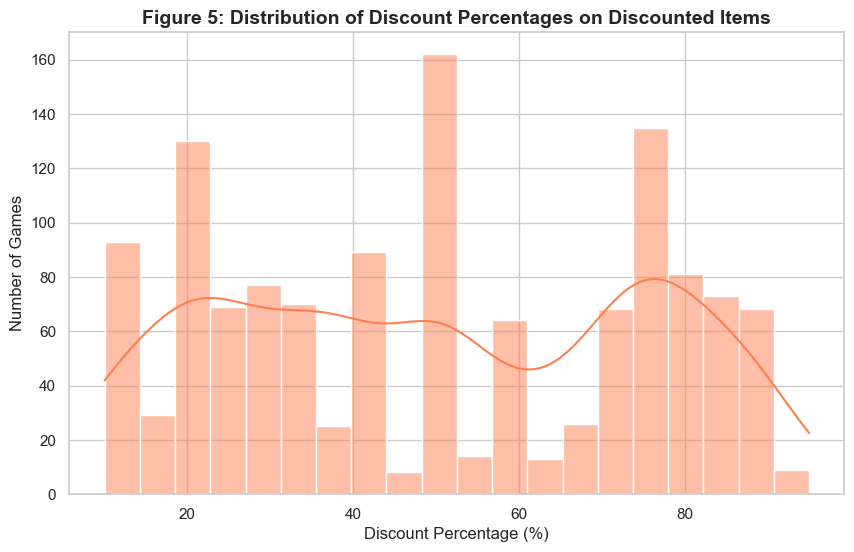

Share of discounted items: 38.58%
count    1303.000000
mean       50.054275
std        25.107759
min        10.000000
25%        28.330000
50%        50.020000
75%        75.020000
max        95.020000
Name: discount_percent, dtype: float64


In [7]:
# Chart 5: Discount percentage distribution
discounted_df = df.dropna(subset=['discount_percent'])

plt.figure(figsize=(10, 6))
sns.histplot(discounted_df['discount_percent'], bins=20, color='coral', kde=True)
plt.title('Figure 5: Distribution of Discount Percentages on Discounted Items', fontsize=14, fontweight='bold')
plt.xlabel('Discount Percentage (%)', fontsize=12)
plt.ylabel('Number of Games', fontsize=12)
plt.show()

print(f"Share of discounted items: {len(discounted_df) / len(df) * 100:.2f}%")
print(discounted_df['discount_percent'].describe())

**Interpretation (Q5):** 
- Approximately 38.6% of products in the top sellers list feature active discounts. 
- The mean discount percentage is around 50.05%, with most discounts clustering between 25% and 75% off.

--- 
## Question 6 (Original Custom Question): How do Free-to-Play games compare in volume and rank distribution versus Paid games?

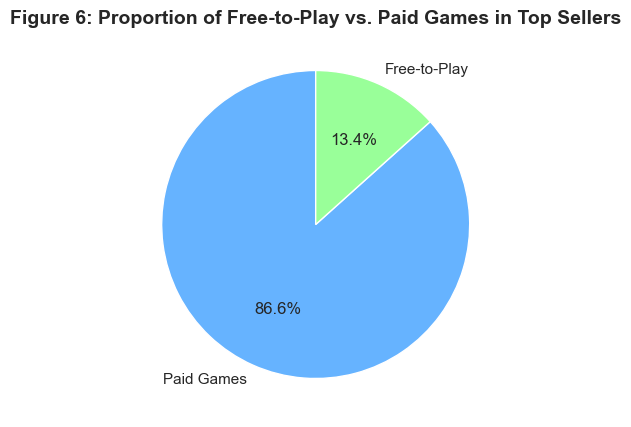

In [8]:
# Chart 6: Free vs Paid proportion across top ranks
df['is_free'] = df['price_usd'] == 0
free_counts = df['is_free'].value_counts()

plt.figure(figsize=(7, 5))
plt.pie(free_counts, labels=['Paid Games', 'Free-to-Play'], autopct='%1.1f%%', colors=['#66b3ff','#99ff99'], startangle=90)
plt.title('Figure 6: Proportion of Free-to-Play vs. Paid Games in Top Sellers', fontsize=14, fontweight='bold')
plt.show()

**Interpretation (Q6 - Custom Question):** 
- Free-to-Play games occupy a significant portion of Steam's top sellers list, demonstrating that user engagement and player acquisition drive top-seller ranking just as much as direct unit sales revenue.